# 03 · Píxeles, longitud exacta y R² clásico

Se repiten exactamente los ejemplos calculados de Fundamentos: once trazas oblicuas con agrupamiento, 100 segmentos aleatorios y un Cantor finito de siete niveles. Se usa Python sin QGIS. Las funciones versionadas generan geometrías y llaman al mismo núcleo de MUSA.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from shapely.geometry import LineString, box
from pyproj import CRS

started_wall, started_cpu = time.perf_counter(), time.process_time()
repository = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/musa").is_dir())
sys.path.insert(0, str(repository / "src"))
sys.path.insert(0, str(repository / "scripts"))
from musa import MUSA, ScalingOptions, assess_lineament_scaling, write_scaling_reports
crs = CRS.from_proj4("+proj=eqc +R=6371000 +units=m +no_defs +type=crs")
lines = [LineString([(1000, 1500), (9000, 6500)])]
domain = box(0, 0, 10000, 10000)
scales = np.geomspace(10, 1000, 16)
model = MUSA.from_line_geometries(lines, domain, crs, q_values=[0, 1, 2])
output = Path(os.environ.get("MUSA_NOTEBOOK_OUTPUT_ROOT", repository / "outputs/notebooks")) / "03_classic_and_exact_length"
output.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    target = output / (name + ".png")
    figure.savefig(target, dpi=120, bbox_inches="tight")
    display(Image(filename=str(target)))
    plt.close(figure)
print("Synthetic inputs; unlocated model metres. Outputs:", output.name)


Synthetic inputs; unlocated model metres. Outputs: 03_classic_and_exact_length


## Longitud frente a área de tinta

Se conserva origen (0,0), cajas 2…32 m y seis configuraciones de píxel/grosor. Cada celda exacta recibe longitud geométrica; cada píxel binario aporta su área una vez.

,measure,D0,D1,D2
0,Exact length,1.174975,1.309507,1.420472
1,0.5 m/px; 1 px,1.162490,1.309358,1.423804
2,0.5 m/px; 3 px,1.244553,1.360815,1.467720
3,1 m/px; 1 px,1.147798,1.296880,1.410435
4,1 m/px; 3 px,1.310082,1.401151,1.474758
5,2 m/px; 1 px,1.114651,1.279033,1.405983
6,2 m/px; 3 px,1.407951,1.497009,1.549651


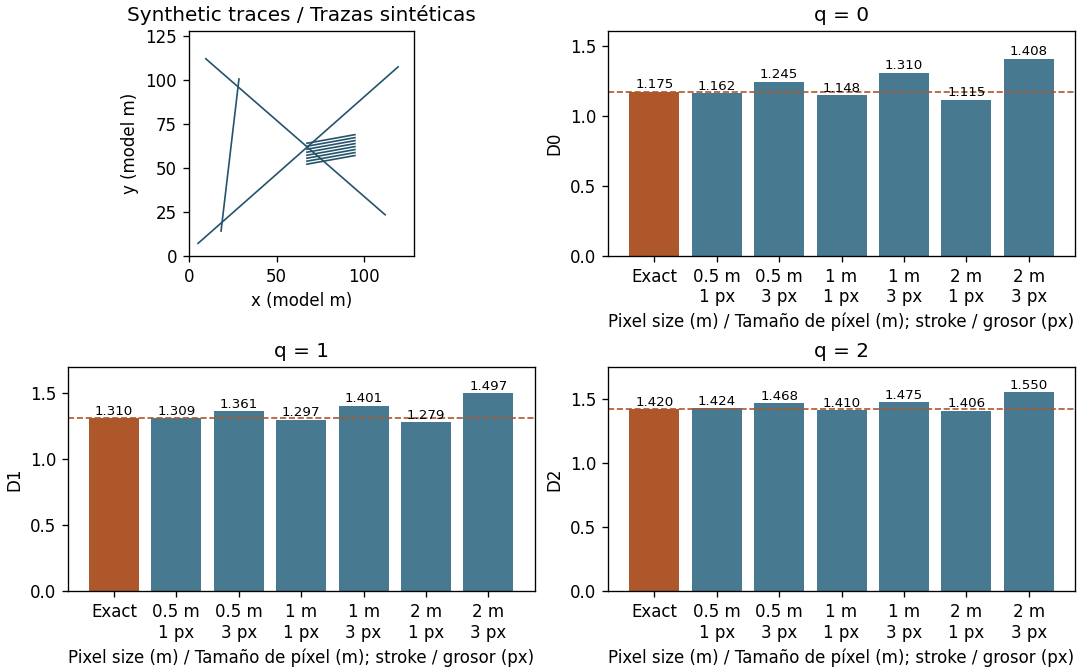

In [2]:
from knowledge_examples import raster_comparison, finite_cantor, random_rods
from build_knowledge_figure import build_examples
comparison = raster_comparison()
table = pd.DataFrame([dict(measure=row["label"], D0=row["dimensions"][0], D1=row["dimensions"][1], D2=row["dimensions"][2]) for row in comparison["rows"]])
display(table)
np.testing.assert_allclose(comparison["rows"][0]["total_lengths"], comparison["total_geometric_length"], rtol=1e-12)
assert abs(table.iloc[-1].D0-table.iloc[0].D0) > .2
table.to_csv(output / "raster_vs_length.csv", index=False)
build_examples(output)
display(Image(filename=str(output / "knowledge_raster.png")))

## R² alto y curvatura con 24 escalas

Se repite el control de 100 segmentos aleatorios de 1000 m, semilla 42, cajas geométricas de 50 a 2000 m y resolución 1 m. Los umbrales son los actuales del núcleo.

D_BC: 1.2361406289876489 R2: 0.9923639034532453


,q,status,dimension,reasons
0,0.0,not_supported,1.243536,"[quadratic_predicts_better, segmented_predicts..."
1,1.0,compatible_finite_range,1.276993,[]
2,2.0,compatible_finite_range,1.295369,[]


,gain_effect,effect,cv_ratio,ratio
quadratic,0.030101,-0.000101,0.247273,-0.502727
segmented,0.030334,-0.000334,0.241462,-0.508538


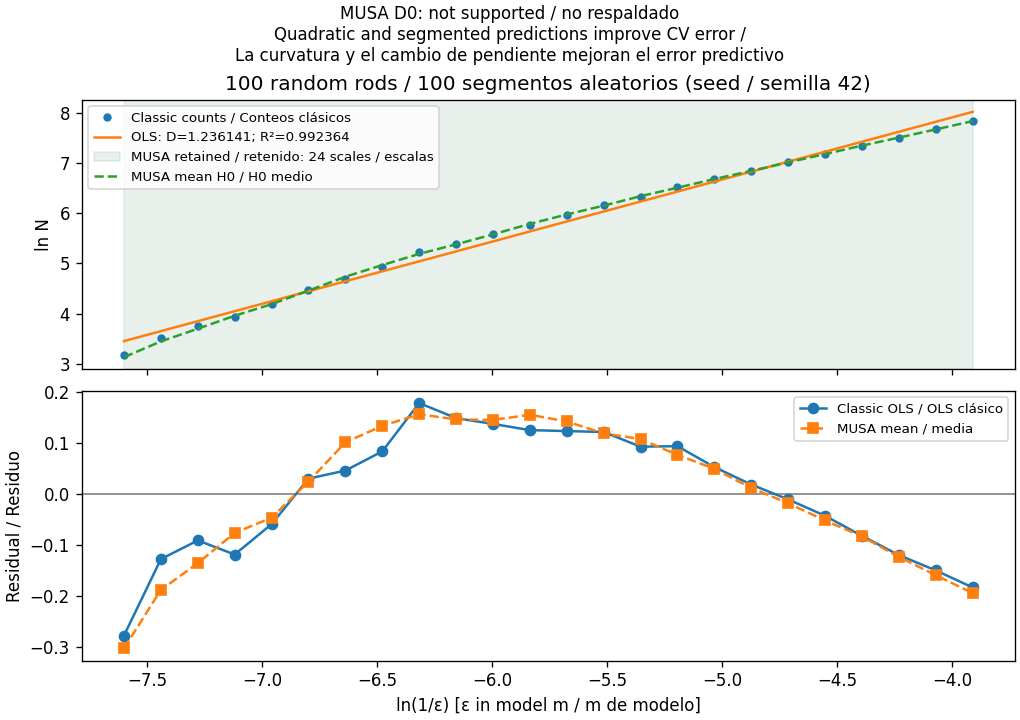

In [3]:
rods = random_rods()
row = rods["assessment"]["q_results"][0]
assert rods["classic"]["r2"] > .99
assert len(rods["assessment"]["used_scales_m"]) == 24
assert row["status"] == "not_supported"
assert {"quadratic_predicts_better", "segmented_predicts_better"} <= set(row["reasons"])
print("D_BC:", rods["classic"]["dimension"], "R2:", rods["classic"]["r2"])
display(pd.DataFrame(rods["assessment"]["q_results"])[["q", "status", "dimension", "reasons"]])
display(pd.DataFrame(row["margins"]["curvature"]).T)
display(Image(filename=str(output / "knowledge_rods.png")))

## Cantor: valor clásico correcto y cuatro escalas

El clásico acierta ln(2)/ln(3). MUSA se abstiene por contar con cuatro escalas frente al mínimo ocho.

D_BC correcto: 0.6309297535714569


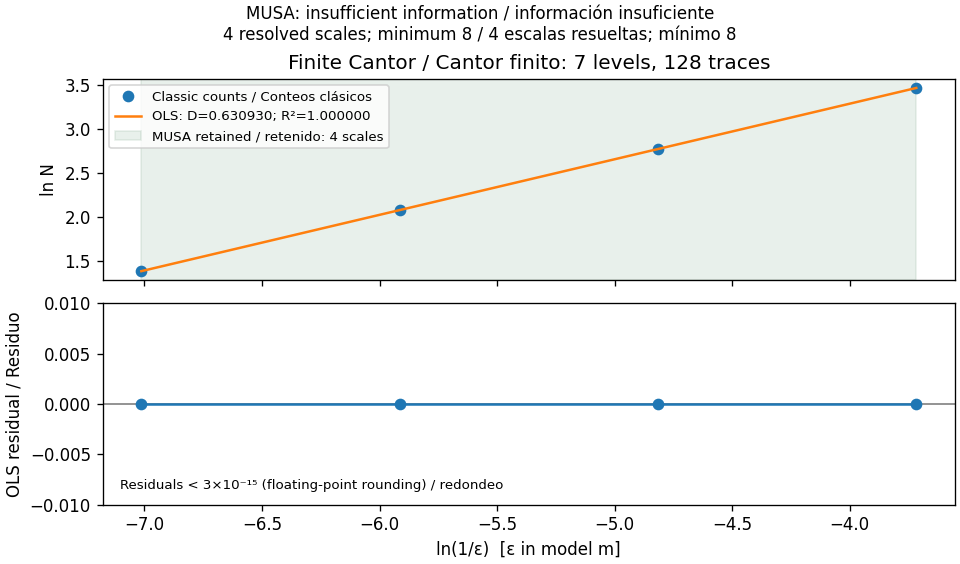

In [4]:
cantor = finite_cantor()
assert np.isclose(cantor["classic"]["dimension"], np.log(2)/np.log(3))
assert all(row["status"] == "insufficient_information" for row in cantor["assessment"]["q_results"])
print("D_BC correcto:", cantor["classic"]["dimension"])
display(Image(filename=str(output / "knowledge_cantor.png")))

In [5]:
metrics = dict(wall_seconds=time.perf_counter()-started_wall,
               cpu_seconds_kernel=time.process_time()-started_cpu)
(output / "execution.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics))


{"wall_seconds": 4.466921399999592, "cpu_seconds_kernel": 4.40625}
